# Rank1 on BRIGHT: reproduction of Table 1

Rank1-7B reranks the authors' BM25 top-100 (BM25 on GPT-4o reasoning queries) of two BRIGHT subsets, Biology and TheoremQA-theorems. `bright_rerank.py` follows the authors' `rank1.predict`: same prompt template, same `prompts.py`, same generation settings, score = P(true). The three runs differ only in the setting under test:

| Run | Reasoning | Dataset prompt | Tests |
|---|---|---|---|
| R1 | yes | authors' | reproduction of Table 1 (48.8 / 37.8) |
| R2 | no | authors' | what reasoning adds |
| R3 | yes | none (raw query) | what the authors' prompt adds |

The three runs take about 14 h on two T4s, more than a Kaggle session (12 h): R1 and R2 ran in a first session, R3 and the report in a second one that started from the first session's runs. The outputs below are those of the two sessions.

In [ ]:
import os
os.environ.update(HF_HUB_DISABLE_PROGRESS_BARS="1", HF_DATASETS_DISABLE_PROGRESS_BARS="1")
MODEL = "jhu-clsp/rank1-7b"
NUM_GPUS = 2
QUERIES_PER_BATCH = 1      # the same for all runs: batching changes results slightly
WORK = "/kaggle/working"
PY = "/tmp/rank1env/bin/python"     # python 3.11 for vllm 0.7.2 (kaggle is on 3.13)
RF = f"{WORK}/rank1-run-files"
SETTINGS = {"R1": ("reason", "authors"), "R2": ("noreason", "authors"), "R3": ("reason", "raw")}

## Setup

In [ ]:
!pip install -q uv
!uv venv /tmp/rank1env --python 3.11 -q
!uv pip install -q --python /tmp/rank1env/bin/python vllm==0.7.2 transformers==4.48.2 datasets==3.2.0 huggingface-hub==0.28.1 numpy==1.26.4 pyarrow==17.0.0 setuptools scipy pytrec-eval-terrier 2>&1 | tail -3
!{PY} -c "import sys, vllm, torch; print('python', sys.version.split()[0], '| vllm', vllm.__version__, '| torch', torch.__version__, '| GPUs', torch.cuda.device_count())"
!test -d {WORK}/rank1 || git clone -q --depth 1 https://github.com/orionw/rank1 {WORK}/rank1


INFO 11-15 07:19:07 __init__.py:190] Automatically detected platform cuda.
python 3.11.18 | vllm 0.7.2 | torch 2.5.1+cu124 | GPUs 2


In [ ]:
%%writefile /kaggle/working/bright_common.py
"""Shared helpers for the Rank1 BRIGHT reproduction (R1-R3).

Everything here mirrors what the authors' code does (orionw/rank1 + their MTEB fork,
commit 22f49e27), so that differences in results come from the setting we change,
not from data handling.
"""
from __future__ import annotations

import json
import os
import sys
from pathlib import Path

# Dataset revision pinned in the authors' MTEB fork (mteb/tasks/Retrieval/eng/BrightRetrieval.py)
BRIGHT_REPO = "xlangai/BRIGHT"
BRIGHT_REVISION = "0dc152a5d69327d457c0390c692baf8e5808424b"

# First-stage candidates used by the authors (run_mteb.py):
#   rank1-run-files/{subtask}_bm25_long_False/score.json   (split "standard", top_k=100)
RUNFILES_REPO = "jhu-clsp/rank1-run-files"
SUBSETS = ["biology", "theoremqa_theorems"]


def runfile_path(runfiles_dir: str | Path, subset: str) -> Path:
    return Path(runfiles_dir) / f"{subset}_bm25_long_False" / "score.json"


def load_bright(subset: str, cache_dir: str | None = None):
    """Return (corpus, queries, qrels) exactly as the authors' MTEB loader builds them
    for the 'standard' split: corpus text = `content`, query = `query`,
    qrels = gold_ids with relevance 1. Note: like MTEB, BRIGHT's `excluded_ids`
    are NOT removed (the official BRIGHT scorer removes them)."""
    from datasets import load_dataset

    docs = load_dataset(BRIGHT_REPO, "documents", split=subset,
                        revision=BRIGHT_REVISION, cache_dir=cache_dir)
    examples = load_dataset(BRIGHT_REPO, "examples", split=subset,
                            revision=BRIGHT_REVISION, cache_dir=cache_dir)
    corpus = {d["id"]: d["content"] for d in docs}
    queries = {e["id"]: e["query"] for e in examples}
    qrels = {e["id"]: {g: 1 for g in e["gold_ids"]} for e in examples}
    return corpus, queries, qrels


def top_k_candidates(first_stage: dict, qid: str, corpus: dict, k: int = 100) -> list[str]:
    """Same selection as MTEB's search_cross_encoder: sort the previous scores
    descending (stable sort, so ties keep file order), take the top k, drop ids
    missing from the corpus."""
    q = first_stage[qid]
    ranked = [d for d, _ in sorted(q.items(), key=lambda kv: kv[1], reverse=True)][:k]
    return [d for d in ranked if d in corpus]


def get_authors_prompt(rank1_repo: str | Path, subset: str) -> str:
    """Load the dataset prompt verbatim from the authors' prompts.py
    (BrightRetrieval_<subset> if present, else the generic BrightRetrieval one)."""
    sys.path.insert(0, str(Path(rank1_repo).resolve()))
    from prompts import get_prompt  # noqa: E402  (authors' file)
    p = get_prompt("BrightRetrieval", subset)
    assert p is not None, f"No prompt for BrightRetrieval/{subset}"
    return p


def build_prompt(query: str, passage: str, dataset_prompt: str | None) -> str:
    """Verbatim copy of rank1.return_prompt."""
    query = dataset_prompt.replace("FILL_QUERY_HERE", query) if dataset_prompt else query
    return "Determine if the following passage is relevant to the query. " \
           "Answer only with 'true' or 'false'.\n" \
           f"Query: {query}\n" \
           f"Passage: {passage}\n" \
           "<think>"


def save_json(obj, path: str | Path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f)
    os.replace(tmp, path)


def load_json(path: str | Path):
    with open(path) as f:
        return json.load(f)


Writing /kaggle/working/bright_common.py


In [ ]:
%%writefile /kaggle/working/bright_rerank.py
#!/usr/bin/env python
"""Rank1 reranking of the BRIGHT top-100, faithful to orionw/rank1 (rank1.py), plus
per-query checkpointing, a no-reasoning mode and a raw-query mode.

    R1: --mode reason   --prompt authors
    R2: --mode noreason --prompt authors
    R3: --mode reason   --prompt raw

Outputs in --out:
    pairs.jsonl   one line per (query, doc): P(true), tokens, seconds, cap flag, reasoning text
    run.json      {qid: {docid: P(true)}} in BM25 order (ties fall back to BM25)
    qrels.json    gold labels (for bright_eval.py)
    config.json   all settings + an example prompt
"""
from __future__ import annotations

import argparse
import json
import math
import os
import random
import shutil
import time
from pathlib import Path

from bright_common import (build_prompt, get_authors_prompt, load_bright, load_json,
                           runfile_path, save_json, top_k_candidates)

# How the reasoning block is closed in --mode noreason. Rank1's own fallback
# (_fix_incomplete_responses) appends "\n<reasoning>\n</think>" and then reads the
# next token; with an empty reasoning this is the format below.
NOREASON_SUFFIX = "\n</think>"


class Rank1VLLM:
    """Same generation and scoring as rank1.rank1, without the MTEB wrapper."""

    def __init__(self, model, num_gpus, context_size, max_output_tokens, dtype,
                 gpu_memory_utilization, enforce_eager, seed):
        from transformers import AutoTokenizer
        from vllm import LLM, SamplingParams
        self.SamplingParams = SamplingParams
        self.tok = AutoTokenizer.from_pretrained(model)
        self.true_token = self.tok(" true", add_special_tokens=False).input_ids[0]
        self.false_token = self.tok(" false", add_special_tokens=False).input_ids[0]
        self.llm = LLM(model=model, tensor_parallel_size=int(num_gpus), trust_remote_code=True,
                       max_model_len=context_size, gpu_memory_utilization=gpu_memory_utilization,
                       dtype=dtype, enforce_eager=enforce_eager, seed=seed)
        self.reason_params = SamplingParams(
            temperature=0, max_tokens=max_output_tokens, logprobs=20,
            stop=["</think> true", "</think> false"], skip_special_tokens=False)
        self.answer_params = SamplingParams(
            temperature=0, max_tokens=1, logprobs=20,
            allowed_token_ids=[self.true_token, self.false_token], skip_special_tokens=False)

    def _score(self, logprobs_step):
        lt = logprobs_step[self.true_token].logprob
        lf = logprobs_step[self.false_token].logprob
        t, f = math.exp(lt), math.exp(lf)
        return t / (t + f)

    def _force_answer(self, prompts, texts):
        """Verbatim logic of rank1._fix_incomplete_responses."""
        cleaned = []
        for text in texts:
            text = text.rstrip()
            if not text.endswith(('.', '!', '?')):
                last = max(text.rfind('.'), text.rfind('!'), text.rfind('?'))
                if last != -1:
                    text = text[:last + 1]
            cleaned.append(text.strip())
        forced = [f"{p}\n{c}\n</think>" for p, c in zip(prompts, cleaned)]
        outs = self.llm.generate(forced, self.answer_params, use_tqdm=False)
        res = []
        for o in outs:
            try:
                lp = o.outputs[0].logprobs[-1]
                assert self.true_token in lp and self.false_token in lp
                res.append((o.outputs[0].text, len(o.outputs[0].token_ids), self._score(lp)))
            except Exception as e:  # authors set 0.5 in this case
                print(f"force-answer failed, score 0.5: {e}")
                res.append((o.outputs[0].text, len(o.outputs[0].token_ids), 0.5))
        return res

    def score_reason(self, prompts):
        outs = self.llm.generate(prompts, self.reason_params, use_tqdm=False)
        rows = [None] * len(prompts)
        bad = []
        for i, o in enumerate(outs):
            out = o.outputs[0]
            base = {"text": out.text, "gen_tokens": len(out.token_ids),
                    "prompt_tokens": len(o.prompt_token_ids),
                    "hit_cap": out.finish_reason == "length", "forced": False}
            try:
                lp = out.logprobs[-1]
                ok = self.true_token in lp and self.false_token in lp
            except Exception:
                ok = False
            if ok:
                base["p_true"] = self._score(lp)
                rows[i] = base
            else:
                rows[i] = base
                bad.append(i)
        if bad:
            fixed = self._force_answer([prompts[i] for i in bad], [rows[i]["text"] for i in bad])
            for i, (txt, n, s) in zip(bad, fixed):
                # authors overwrite text/count with the forced step; we keep the
                # reasoning text and add the forced token to the count
                rows[i]["p_true"] = s
                rows[i]["gen_tokens"] += n
                rows[i]["forced"] = True
        return rows

    def score_noreason(self, prompts):
        forced = [p + NOREASON_SUFFIX for p in prompts]
        outs = self.llm.generate(forced, self.answer_params, use_tqdm=False)
        rows = []
        for o in outs:
            out = o.outputs[0]
            lp = out.logprobs[-1]
            rows.append({"text": "", "gen_tokens": len(out.token_ids),
                         "prompt_tokens": len(o.prompt_token_ids),
                         "hit_cap": False, "forced": False, "p_true": self._score(lp)})
        return rows


class DummyBackend:
    """For testing the pipeline without a GPU."""

    def __init__(self, seed=0):
        self.rng = random.Random(seed)

    def score_reason(self, prompts):
        time.sleep(0.001 * len(prompts))
        return [{"text": "dummy reasoning.", "gen_tokens": self.rng.randint(50, 900),
                 "prompt_tokens": len(p) // 4, "hit_cap": self.rng.random() < 0.02,
                 "forced": False, "p_true": self.rng.random()} for p in prompts]

    def score_noreason(self, prompts):
        return [{"text": "", "gen_tokens": 1, "prompt_tokens": len(p) // 4, "hit_cap": False,
                 "forced": False, "p_true": self.rng.choice([0.001, 0.5, 0.999])} for p in prompts]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--subset", required=True, choices=["biology", "theoremqa_theorems"])
    ap.add_argument("--mode", required=True, choices=["reason", "noreason"])
    ap.add_argument("--prompt", required=True, choices=["authors", "raw"])
    ap.add_argument("--out", required=True)
    ap.add_argument("--runfiles", default="rank1-run-files")
    ap.add_argument("--rank1_repo", default="rank1")
    ap.add_argument("--model", default="jhu-clsp/rank1-7b")
    ap.add_argument("--num_gpus", type=int, default=2)
    ap.add_argument("--top_k", type=int, default=100)
    ap.add_argument("--context_size", type=int, default=16000)       # authors' default
    ap.add_argument("--max_output_tokens", type=int, default=8192)   # authors' default
    ap.add_argument("--dtype", default="float16")                    # authors' default
    ap.add_argument("--gpu_memory_utilization", type=float, default=0.9)
    ap.add_argument("--enforce_eager", action="store_true")
    ap.add_argument("--queries_per_batch", type=int, default=1,
                    help="queries sent to vLLM at once; checkpoint after each batch")
    ap.add_argument("--max_queries", type=int, default=None, help="smoke tests")
    ap.add_argument("--resume_from", default=None,
                    help="dir with a previous pairs.jsonl (e.g. a Kaggle input) to continue from")
    ap.add_argument("--backend", default="vllm", choices=["vllm", "dummy"])
    ap.add_argument("--data_json", default=None,
                    help="testing only: json with corpus/queries/qrels instead of HF datasets")
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    out = Path(args.out)
    out.mkdir(parents=True, exist_ok=True)
    pairs_path = out / "pairs.jsonl"
    if args.resume_from and not pairs_path.exists():
        src = Path(args.resume_from) / "pairs.jsonl"
        if src.exists():
            shutil.copy(src, pairs_path)
            print(f"Resuming from {src}")

    # ---- data
    if args.data_json:
        d = load_json(args.data_json)
        corpus, queries, qrels = d["corpus"], d["queries"], d["qrels"]
    else:
        corpus, queries, qrels = load_bright(args.subset)
    save_json(qrels, out / "qrels.json")
    first_stage = load_json(runfile_path(args.runfiles, args.subset))
    dataset_prompt = get_authors_prompt(args.rank1_repo, args.subset) if args.prompt == "authors" else None

    qids = [q for q in queries if q in first_stage]
    missing = [q for q in queries if q not in first_stage]
    if missing:
        print(f"WARNING: {len(missing)} queries have no first-stage results: {missing[:5]}")
    if args.max_queries:
        qids = qids[:args.max_queries]

    done = set()
    if pairs_path.exists():
        with open(pairs_path) as f:
            for line in f:
                done.add(json.loads(line)["qid"])
    todo = [q for q in qids if q not in done]
    n_pairs = sum(len(top_k_candidates(first_stage, q, corpus, args.top_k)) for q in qids)
    print(f"{args.subset} | mode={args.mode} prompt={args.prompt} | {len(qids)} queries, "
          f"{n_pairs} pairs | {len(done)} queries already done, {len(todo)} to go")

    example = build_prompt(queries[qids[0]], corpus[top_k_candidates(first_stage, qids[0], corpus, 1)[0]],
                           dataset_prompt)
    save_json({**vars(args), "dataset_prompt": dataset_prompt, "noreason_suffix": NOREASON_SUFFIX,
               "example_prompt": example, "n_queries": len(qids), "n_pairs": n_pairs}, out / "config.json")
    print("Example prompt:\n" + example[:1500] + ("\n..." if len(example) > 1500 else ""))

    # ---- model
    if args.backend == "vllm":
        os.environ.setdefault("VLLM_ALLOW_LONG_MAX_MODEL_LEN", "1")
        os.environ.setdefault("VLLM_WORKER_MULTIPROC_METHOD", "spawn")
        model = Rank1VLLM(args.model, args.num_gpus, args.context_size, args.max_output_tokens,
                          args.dtype, args.gpu_memory_utilization, args.enforce_eager, args.seed)
    else:
        model = DummyBackend(args.seed)
    scorer = model.score_reason if args.mode == "reason" else model.score_noreason

    # ---- rerank, checkpoint after every batch of queries
    t_start = time.time()
    for b in range(0, len(todo), args.queries_per_batch):
        batch_q = todo[b:b + args.queries_per_batch]
        meta, prompts = [], []
        for q in batch_q:
            for rank, d in enumerate(top_k_candidates(first_stage, q, corpus, args.top_k), 1):
                meta.append((q, d, rank, first_stage[q][d]))
                prompts.append(build_prompt(queries[q], corpus[d], dataset_prompt))
        t0 = time.time()
        rows = scorer(prompts)
        dt = time.time() - t0
        with open(pairs_path, "a") as f:
            for (q, d, rank, bm25), r in zip(meta, rows):
                f.write(json.dumps({"qid": q, "docid": d, "bm25_rank": rank, "bm25_score": bm25,
                                    "rel": qrels.get(q, {}).get(d, 0),
                                    "sec_per_pair": dt / len(prompts), **r}) + "\n")
            f.flush()
            os.fsync(f.fileno())
        done_n = len(done) + b + len(batch_q)
        el = time.time() - t_start
        eta = el / (b + len(batch_q)) * (len(todo) - b - len(batch_q))
        print(f"[{done_n}/{len(qids)}] {len(prompts)} pairs in {dt:.1f}s "
              f"({dt / len(prompts):.3f} s/pair) | elapsed {el / 3600:.2f} h, ETA {eta / 3600:.2f} h",
              flush=True)

    # ---- run file in BM25 order
    run = {}
    with open(pairs_path) as f:
        rows = [json.loads(l) for l in f]
    for r in sorted(rows, key=lambda r: (qids.index(r["qid"]) if r["qid"] in qids else 1e9, r["bm25_rank"])):
        run.setdefault(r["qid"], {})[r["docid"]] = r["p_true"]
    save_json(run, out / "run.json")
    print(f"Done. Wrote {out / 'run.json'} ({len(run)} queries).")


if __name__ == "__main__":
    main()


Writing /kaggle/working/bright_rerank.py


In [ ]:
%%writefile /kaggle/working/bright_eval.py
#!/usr/bin/env python
"""Evaluation and analyses for the Rank1 BRIGHT runs.

  python bright_eval.py first-stage --subset biology --runfiles rank1-run-files [--qrels q.json]
      sanity check: nDCG@10 of the authors' BM25 top-100 (53.6 / 20.8)
  python bright_eval.py score runs/R1_biology [runs/R2_biology ...]
      nDCG@10, cost (tokens, s/pair, cap share) and polarization per run
  python bright_eval.py compare runs/R1_biology runs/R2_biology
      paired t-test and bootstrap 95% CI over queries (B minus A)

nDCG@10 uses trec_eval's definition (linear gain, log2 discount, ideal DCG from all
qrels). Ties are broken by the run's own order (BM25 order for our runs). When
pytrec_eval is installed we also print its value (it breaks ties by doc id), which is
what the authors' MTEB evaluation reports.
"""
from __future__ import annotations

import argparse
import json
import math
import random
import statistics
from pathlib import Path

from bright_common import load_json, runfile_path, top_k_candidates


def ndcg_at_k(ranked: list[str], qrel: dict[str, int], k: int = 10) -> float:
    dcg = sum(qrel.get(d, 0) / math.log2(i + 2) for i, d in enumerate(ranked[:k]))
    ideal = sorted(qrel.values(), reverse=True)[:k]
    idcg = sum(g / math.log2(i + 2) for i, g in enumerate(ideal))
    return dcg / idcg if idcg > 0 else 0.0


def per_query_ndcg(run: dict, qrels: dict, k: int = 10) -> dict[str, float]:
    """run: {qid: {docid: score}}; dict order = tie-break order."""
    res = {}
    for qid, qrel in qrels.items():
        if not any(v > 0 for v in qrel.values()):
            continue
        docs = run.get(qid, {})
        order = {d: i for i, d in enumerate(docs)}
        ranked = sorted(docs, key=lambda d: (-docs[d], order[d]))
        res[qid] = ndcg_at_k(ranked, qrel, k)
    return res


def pytrec_ndcg(run: dict, qrels: dict) -> float | None:
    try:
        import pytrec_eval
    except ImportError:
        return None
    qrels = {q: {d: int(v) for d, v in r.items()} for q, r in qrels.items()}
    run = {q: {d: float(s) for d, s in r.items()} for q, r in run.items() if q in qrels}
    ev = pytrec_eval.RelevanceEvaluator(qrels, {"ndcg_cut.10"})
    scores = ev.evaluate(run)
    vals = [scores[q]["ndcg_cut_10"] if q in scores else 0.0 for q in qrels]
    return sum(vals) / len(vals)


def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else float("nan")


def load_rows(run_dir: Path) -> list[dict]:
    with open(run_dir / "pairs.jsonl") as f:
        return [json.loads(l) for l in f]


def cmd_first_stage(a):
    if a.qrels:
        qrels = load_json(a.qrels)
        corpus = None
    else:
        from bright_common import load_bright
        corpus, _, qrels = load_bright(a.subset)
    fs = load_json(runfile_path(a.runfiles, a.subset))
    run = {}
    for q in qrels:
        if q not in fs:
            continue
        cand = top_k_candidates(fs, q, corpus if corpus is not None else fs[q], a.top_k)
        run[q] = {d: fs[q][d] for d in cand}
    pq = per_query_ndcg(run, qrels)
    n_cand = sum(len(v) for v in run.values())
    print(f"{a.subset}: {len(run)} queries, {n_cand} candidate pairs (top-{a.top_k})")
    print(f"  nDCG@10 (ours, tie=file order) = {100 * mean(pq.values()):.1f}")
    pt = pytrec_ndcg(run, qrels)
    if pt is not None:
        print(f"  nDCG@10 (pytrec_eval)          = {100 * pt:.1f}")
    target = {"biology": 53.6, "theoremqa_theorems": 20.2}.get(a.subset)
    if target:
        print(f"  target from the plan            = {target}")


def summarize(run_dir: Path) -> dict:
    rows = load_rows(run_dir)
    qrels = load_json(run_dir / "qrels.json")
    run = load_json(run_dir / "run.json") if (run_dir / "run.json").exists() else None
    if run is None:  # run still in progress: rebuild from pairs
        run = {}
        for r in sorted(rows, key=lambda r: r["bm25_rank"]):
            run.setdefault(r["qid"], {})[r["docid"]] = r["p_true"]
    qrels_eval = {q: qrels[q] for q in run}  # only queries that were scored
    pq = per_query_ndcg(run, qrels_eval)
    p = [r["p_true"] for r in rows]
    return {
        "run": run_dir.name,
        "queries": len(pq),
        "pairs": len(rows),
        "ndcg10": 100 * mean(pq.values()),
        "ndcg10_pytrec": (lambda v: None if v is None else 100 * v)(pytrec_ndcg(run, qrels_eval)),
        "gen_tokens_per_pair": mean(r["gen_tokens"] for r in rows),
        "median_gen_tokens": statistics.median(r["gen_tokens"] for r in rows),
        "sec_per_pair": mean(r["sec_per_pair"] for r in rows),
        "cap_share": mean(r["hit_cap"] for r in rows),
        "forced_share": mean(r["forced"] for r in rows),
        "share_p_gt_0.99": mean(x > 0.99 for x in p),
        "share_p_lt_0.01": mean(x < 0.01 for x in p),
        "polarized_share": mean(x > 0.99 or x < 0.01 for x in p),
    }


def cmd_score(a):
    out = []
    for d in a.run_dirs:
        s = summarize(Path(d))
        out.append(s)
        print(f"\n== {s['run']}  ({s['queries']} queries, {s['pairs']} pairs)")
        print(f"  nDCG@10            {s['ndcg10']:.1f}" +
              (f"   (pytrec_eval {s['ndcg10_pytrec']:.1f})" if s["ndcg10_pytrec"] is not None else ""))
        print(f"  tokens / pair      {s['gen_tokens_per_pair']:.0f} (median {s['median_gen_tokens']:.0f})")
        print(f"  seconds / pair     {s['sec_per_pair']:.3f}")
        print(f"  hit token cap      {100 * s['cap_share']:.2f}%   forced answer {100 * s['forced_share']:.2f}%")
        print(f"  P(true) >0.99 / <0.01   {100 * s['share_p_gt_0.99']:.1f}% / {100 * s['share_p_lt_0.01']:.1f}%")
    if a.json:
        Path(a.json).write_text(json.dumps(out, indent=2))
        print(f"\nSaved {a.json}")


def paired_stats(a_vals: list[float], b_vals: list[float], n_boot=10000, seed=0):
    from scipy import stats
    diffs = [b - x for x, b in zip(a_vals, b_vals)]
    t = stats.ttest_rel(b_vals, a_vals)
    rng = random.Random(seed)
    n = len(diffs)
    boots = sorted(mean(diffs[rng.randrange(n)] for _ in range(n)) for _ in range(n_boot))
    return {"delta": mean(diffs), "p": float(t.pvalue),
            "ci95": [boots[int(0.025 * n_boot)], boots[int(0.975 * n_boot) - 1]],
            "wins": sum(d > 0 for d in diffs), "ties": sum(d == 0 for d in diffs),
            "losses": sum(d < 0 for d in diffs), "n": n}


def cmd_collect(a):
    """Join the authors' outputs (MTEB predictions file = final P(true) scores) with our
    generation log, pair by pair, by rebuilding each prompt exactly as rank1.predict does."""
    import glob
    import hashlib
    from bright_common import build_prompt, get_authors_prompt, load_bright, save_json

    run_dir = Path(a.run_dir)
    preds = sorted(glob.glob(str(run_dir / "results" / "**" / "*_predictions.json"), recursive=True))
    assert preds, f"no *_predictions.json under {run_dir / 'results'}"
    pred = load_json(preds[0])
    mteb_json = [p for p in glob.glob(str(run_dir / "results" / "**" / "BrightRetrieval.json"), recursive=True)]

    corpus, queries, qrels = load_bright(a.subset)
    fs = load_json(runfile_path(a.runfiles, a.subset))
    dataset_prompt = None if a.raw else get_authors_prompt(a.rank1_repo, a.subset)

    def base_sha(p):
        i = p.find("<think>")
        return hashlib.sha1((p if i == -1 else p[:i + 7]).encode("utf-8")).hexdigest()

    reason, forced, calls = {}, {}, {}
    with open(run_dir / "generations.jsonl") as f:
        for line in f:
            g = json.loads(line)
            (forced if g["is_forced_step"] else reason)[g["base_sha1"]] = g
            calls[(g["call_seconds"], g["call_size"])] = g["call_seconds"]
    total_sec = sum(calls.values())

    rows, missing = [], 0
    for qid in queries:
        if qid not in fs or qid not in pred:
            continue
        for rank, d in enumerate(top_k_candidates(fs, qid, corpus, 100), 1):
            h = base_sha(build_prompt(queries[qid], corpus[d], dataset_prompt))
            r, fo = reason.get(h), forced.get(h)
            if r is None and fo is None:
                missing += 1
            rows.append({
                "qid": qid, "docid": d, "bm25_rank": rank, "bm25_score": fs[qid][d],
                "rel": qrels.get(qid, {}).get(d, 0), "p_true": pred[qid].get(d, float("nan")),
                "text": r["text"] if r else "",
                "gen_tokens": (r["gen_tokens"] if r else 0) + (fo["gen_tokens"] if fo else 0),
                "prompt_tokens": (r or fo or {}).get("prompt_tokens"),
                "hit_cap": bool(r and r["finish_reason"] == "length"),
                "forced": bool(r and fo),
            })
    for r in rows:
        r["sec_per_pair"] = total_sec / len(rows)
    with open(run_dir / "pairs.jsonl", "w") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
    run = {}
    for r in rows:
        run.setdefault(r["qid"], {})[r["docid"]] = r["p_true"]
    save_json(run, run_dir / "run.json")
    save_json(qrels, run_dir / "qrels.json")
    print(f"{run_dir.name}: {len(rows)} pairs, {len(run)} queries, "
          f"{missing} pairs without a log record ({100 * missing / max(len(rows), 1):.1f}%), "
          f"{total_sec / 3600:.2f} h of generation")
    if missing:
        print("  WARNING: prompts did not match the log; token/cost numbers are incomplete for those pairs")
    for m in mteb_json:
        res = load_json(m)
        try:
            v = res["scores"]["standard"][0]["ndcg_at_10"]
            print(f"  authors' MTEB nDCG@10 = {100 * v:.1f}   ({m})")
        except Exception:
            print(f"  MTEB result file: {m}")


def cmd_compare(a):
    da, db = Path(a.run_a), Path(a.run_b)
    qrels = load_json(da / "qrels.json")
    ra, rb = load_json(da / "run.json"), load_json(db / "run.json")
    common = [q for q in qrels if q in ra and q in rb]
    qa = per_query_ndcg({q: ra[q] for q in common}, {q: qrels[q] for q in common})
    qb = per_query_ndcg({q: rb[q] for q in common}, {q: qrels[q] for q in common})
    qs = [q for q in common if q in qa]
    s = paired_stats([qa[q] for q in qs], [qb[q] for q in qs])
    print(f"{db.name} vs {da.name} over {s['n']} queries")
    print(f"  nDCG@10  {100 * mean(qa[q] for q in qs):.1f} -> {100 * mean(qb[q] for q in qs):.1f}")
    print(f"  delta {100 * s['delta']:+.1f}  p={s['p']:.4f}  "
          f"95% CI [{100 * s['ci95'][0]:+.1f}, {100 * s['ci95'][1]:+.1f}]  "
          f"W/T/L {s['wins']}/{s['ties']}/{s['losses']}")
    if a.json:
        Path(a.json).write_text(json.dumps({"a": da.name, "b": db.name, **s}, indent=2))


def main():
    ap = argparse.ArgumentParser()
    sub = ap.add_subparsers(dest="cmd", required=True)
    p = sub.add_parser("first-stage")
    p.add_argument("--subset", required=True)
    p.add_argument("--runfiles", default="rank1-run-files")
    p.add_argument("--qrels", default=None, help="qrels.json; default loads BRIGHT from HF")
    p.add_argument("--top_k", type=int, default=100)
    p.set_defaults(f=cmd_first_stage)
    p = sub.add_parser("score")
    p.add_argument("run_dirs", nargs="+")
    p.add_argument("--json", default=None)
    p.set_defaults(f=cmd_score)
    p = sub.add_parser("collect")
    p.add_argument("run_dir")
    p.add_argument("--subset", required=True)
    p.add_argument("--runfiles", default="rank1-run-files")
    p.add_argument("--rank1_repo", default="rank1")
    p.add_argument("--raw", action="store_true", help="run used -p (no dataset prompt), i.e. R3")
    p.set_defaults(f=cmd_collect)
    p = sub.add_parser("compare")
    p.add_argument("run_a")
    p.add_argument("run_b")
    p.add_argument("--json", default=None)
    p.set_defaults(f=cmd_compare)
    a = ap.parse_args()
    a.f(a)


if __name__ == "__main__":
    main()


Writing /kaggle/working/bright_eval.py


In [ ]:
%%writefile /kaggle/working/bright_report.py
#!/usr/bin/env python
"""Graphs + tables for the Rank1 BRIGHT runs (R1 reproduction, R2 no-reasoning, R3 raw query).

    python bright_report.py runs/ --out report/

`runs/` is the folder from bright_runs.tgz (subfolders R1_biology, R2_biology, ...,
each with pairs.jsonl, run.json, qrels.json written by `bright_eval.py collect`).
Works with whatever runs exist (e.g. only R1 after the first commit).

Writes to --out:
    report.html        all tables + figures in one page (open in a browser)
    tables.md          the tables in Markdown (paste into README / report)
    fig*.png           one figure per file, 2x resolution, for the slides
"""
from __future__ import annotations

import argparse
import base64
import json
import math
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

from bright_eval import mean, paired_stats, per_query_ndcg  # noqa: E402

SUBSETS = ["biology", "theoremqa_theorems"]
SUBSET_LABEL = {"biology": "Biology", "theoremqa_theorems": "TheoremQA-theorems"}
RUN_LABEL = {"BM25": "BM25 on GPT-4o CoT", "R1": "R1 reasoning", "R2": "R2 no reasoning",
             "R3": "R3 raw query"}
PAPER = {"BM25": {"biology": 53.6, "theoremqa_theorems": 20.2},     # first stage (plan)
         "R1": {"biology": 48.8, "theoremqa_theorems": 37.8}}       # Rank1-7B, Table 1

# Reference palette (dataviz skill): categorical slots 1-3 validate all-pairs; gray = baseline
COL = {"BM25": "#a3a29b", "R1": "#2a78d6", "R2": "#eb6834", "R3": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4df"
POS, NEG = "#2a78d6", "#e34948"   # diverging pair: blue (gain) / red (loss)

plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "axes.titleweight": "bold",
    "axes.titlesize": 11, "legend.frameon": False,
})


def load_run(d: Path):
    rows = [json.loads(l) for l in open(d / "pairs.jsonl")]
    run = json.load(open(d / "run.json"))
    qrels = json.load(open(d / "qrels.json"))
    return rows, run, qrels


def bm25_run(rows):
    run = {}
    for r in sorted(rows, key=lambda r: r["bm25_rank"]):
        run.setdefault(r["qid"], {})[r["docid"]] = r["bm25_score"]
    return run


def collect(runs_dir: Path):
    data = {}   # data[subset][run_id] = dict(rows, run, pq)
    for s in SUBSETS:
        for rid in ["R1", "R2", "R3"]:
            d = runs_dir / f"{rid}_{s}"
            if not (d / "pairs.jsonl").exists():
                continue
            rows, run, qrels = load_run(d)
            q = {k: qrels[k] for k in run}
            data.setdefault(s, {})[rid] = {"rows": rows, "run": run, "qrels": q,
                                           "pq": per_query_ndcg(run, q)}
            if "BM25" not in data[s]:
                b = bm25_run(rows)
                data[s]["BM25"] = {"rows": None, "run": b, "qrels": q, "pq": per_query_ndcg(b, q)}
    return data


def stats_row(e):
    rows = e["rows"]
    out = {"ndcg": 100 * mean(e["pq"].values()), "queries": len(e["pq"])}
    if rows:
        p = [r["p_true"] for r in rows]
        tok = sorted(r["gen_tokens"] for r in rows)
        out.update(pairs=len(rows), tok=mean(tok), tok_med=tok[len(tok) // 2],
                   tok_p95=tok[int(0.95 * (len(tok) - 1))], sec=mean(r["sec_per_pair"] for r in rows),
                   cap=100 * mean(r["hit_cap"] for r in rows),
                   hi=100 * mean(x > 0.99 for x in p), lo=100 * mean(x < 0.01 for x in p))
    return out


# ---------------------------------------------------------------- figures
def fig_ndcg(data, out):
    """Filled bar = ours; hollow bar beside it = the paper's number (BM25 and R1 only)."""
    fig, axes = plt.subplots(1, len(data), figsize=(4.8 * len(data), 3.6), squeeze=False)
    for ax, s in zip(axes[0], data):
        ids = [r for r in ["BM25", "R1", "R2", "R3"] if r in data[s]]
        top = 0
        for i, r in enumerate(ids):
            v = 100 * mean(data[s][r]["pq"].values())
            has_paper = r in PAPER
            xo = i - 0.18 if has_paper else i
            ax.bar(xo, v, width=0.34, color=COL[r], edgecolor="white", linewidth=2)
            ax.text(xo, v + 1, f"{v:.1f}", ha="center", va="bottom", color=INK, fontsize=8.5)
            top = max(top, v)
            if has_paper:
                pv = PAPER[r][s]
                ax.bar(i + 0.18, pv, width=0.34, facecolor="none", edgecolor=COL[r], linewidth=1.5,
                       hatch="////")
                ax.text(i + 0.18, pv + 1, f"{pv}", ha="center", va="bottom", color=INK2, fontsize=8.5)
                top = max(top, pv)
        ax.set_xticks(range(len(ids)), [RUN_LABEL[r].replace(" ", "\n", 1) for r in ids], fontsize=8.5)
        ax.set_ylim(0, top * 1.18)
        ax.set_title(SUBSET_LABEL[s])
        ax.set_ylabel("nDCG@10")
        ax.grid(axis="x", visible=False)
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(facecolor=INK2, label="ours"),
                        Patch(facecolor="none", edgecolor=INK2, hatch="////", label="paper")],
               loc="upper right", ncol=2, fontsize=8.5)
    fig.suptitle("Effectiveness: our runs vs the paper", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(out)
    plt.close(fig)


def fig_cost(data, out):
    fig, axes = plt.subplots(1, len(data), figsize=(4.6 * len(data), 3.4), squeeze=False)
    for ax, s in zip(axes[0], data):
        for rid in ["R1", "R2", "R3"]:
            if rid not in data[s]:
                continue
            st = stats_row(data[s][rid])
            ax.scatter(st["sec"], st["ndcg"], s=80, color=COL[rid], edgecolor="white",
                       linewidth=2, zorder=3)
            off = {"R1": (8, -13), "R2": (8, 4), "R3": (8, 5)}[rid]
            ax.annotate(RUN_LABEL[rid], (st["sec"], st["ndcg"]), xytext=off,
                        textcoords="offset points", fontsize=8.5, color=INK)
        b = 100 * mean(data[s]["BM25"]["pq"].values())
        ax.axhline(b, color=COL["BM25"], lw=1.5, ls=(0, (3, 2)))
        ax.set_xscale("log")
        from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo / 1.6, hi * 2.5)
        ax.xaxis.set_major_locator(FixedLocator([0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.text(ax.get_xlim()[0], b, "  BM25 (no reranking)", va="bottom", fontsize=8, color=INK2)
        ax.set_xlabel("GPU seconds per pair (log, 2×T4)")
        ax.set_ylabel("nDCG@10")
        ax.set_title(SUBSET_LABEL[s])
    fig.suptitle("Cost vs effectiveness", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(out)
    plt.close(fig)


def fig_polarization(data, out):
    rids = [r for r in ["R1", "R2", "R3"] if any(r in data[s] for s in data)]
    fig, axes = plt.subplots(len(data), len(rids), figsize=(3.3 * len(rids), 2.6 * len(data)),
                             squeeze=False, sharex=True, sharey=True)
    bins = [i / 20 for i in range(21)]
    for i, s in enumerate(data):
        for j, rid in enumerate(rids):
            ax = axes[i][j]
            if rid not in data[s]:
                ax.axis("off")
                continue
            p = [r["p_true"] for r in data[s][rid]["rows"]]
            w = [100 / len(p)] * len(p)
            ax.hist(p, bins=bins, weights=w, color=COL[rid], edgecolor="white", linewidth=1)
            st = stats_row(data[s][rid])
            ax.set_title(f"{RUN_LABEL[rid]} · {SUBSET_LABEL[s]}", fontsize=9)
            ax.text(0.5, 0.92, f"<0.01: {st['lo']:.0f}%   >0.99: {st['hi']:.0f}%",
                    transform=ax.transAxes, ha="center", fontsize=8, color=INK)
            if j == 0:
                ax.set_ylabel("% of pairs")
            if i == len(data) - 1:
                ax.set_xlabel("P(true)")
    fig.suptitle("Score polarization: distribution of P(true)", x=0.01, ha="left",
                 fontweight="bold")
    fig.tight_layout()
    fig.savefig(out)
    plt.close(fig)


def fig_tokens(data, out):
    rids = [r for r in ["R1", "R3"] if any(r in data[s] for s in data)]
    if not rids:
        return False
    fig, axes = plt.subplots(1, len(data), figsize=(4.6 * len(data), 3.2), squeeze=False)
    edges = [2 ** (k / 2) for k in range(10, 28)]  # 32 .. 8192+
    for ax, s in zip(axes[0], data):
        for rid in rids:
            if rid not in data[s]:
                continue
            t = [max(r["gen_tokens"], 1) for r in data[s][rid]["rows"]]
            ax.hist(t, bins=edges, weights=[100 / len(t)] * len(t), histtype="step",
                    linewidth=2, color=COL[rid], label=RUN_LABEL[rid])
        ax.axvline(8192, color=INK2, lw=1, ls=(0, (3, 2)))
        ax.text(8192, ax.get_ylim()[1] * 0.95, "cap 8,192 ", ha="right", fontsize=8, color=INK2)
        ax.set_xscale("log")
        ax.set_xlabel("generated tokens per pair (log)")
        ax.set_ylabel("% of pairs")
        ax.set_title(SUBSET_LABEL[s])
        ax.legend(fontsize=8, loc="upper left")
    fig.suptitle("Reasoning length", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(out)
    plt.close(fig)
    return True


def fig_delta(data, a, b, out, title):
    subs = [s for s in data if a in data[s] and b in data[s]]
    if not subs:
        return False
    fig, axes = plt.subplots(1, len(subs), figsize=(4.6 * len(subs), 3.2), squeeze=False)
    for ax, s in zip(axes[0], subs):
        pa, pb = data[s][a]["pq"], data[s][b]["pq"]
        d = sorted(100 * (pb[q] - pa[q]) for q in pa if q in pb)
        ax.bar(range(len(d)), d, width=1.0, color=[POS if v > 0 else NEG if v < 0 else GRID for v in d],
               edgecolor="white", linewidth=0.3)
        ax.axhline(0, color=INK2, lw=0.8)
        w, l = sum(v > 0 for v in d), sum(v < 0 for v in d)
        ax.set_title(f"{SUBSET_LABEL[s]}  (better {w} · worse {l} · same {len(d) - w - l})", fontsize=9.5)
        ax.set_xlabel("queries, sorted by change")
        ax.set_ylabel(f"Δ nDCG@10 ({b} − {a})")
        ax.set_xticks([])
        ax.grid(axis="x", visible=False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(out)
    plt.close(fig)
    return True


# ---------------------------------------------------------------- tables
def tables(data):
    md = []
    md.append("### Effectiveness and cost\n")
    md.append("| Subset | Run | nDCG@10 | Paper | Tokens/pair (median, p95) | s/pair | Hit cap | P(true) <0.01 / >0.99 |")
    md.append("|---|---|---:|---:|---|---:|---:|---|")
    for s in data:
        for rid in ["BM25", "R1", "R2", "R3"]:
            if rid not in data[s]:
                continue
            st = stats_row(data[s][rid])
            paper = PAPER.get(rid, {}).get(s, "")
            if data[s][rid]["rows"]:
                md.append(f"| {SUBSET_LABEL[s]} | {RUN_LABEL[rid]} | {st['ndcg']:.1f} | {paper} | "
                          f"{st['tok']:.0f} ({st['tok_med']}, {st['tok_p95']}) | {st['sec']:.2f} | "
                          f"{st['cap']:.2f}% | {st['lo']:.0f}% / {st['hi']:.0f}% |")
            else:
                md.append(f"| {SUBSET_LABEL[s]} | {RUN_LABEL[rid]} | {st['ndcg']:.1f} | {paper} | – | – | – | – |")
    md.append("\n### Paired comparisons (per query; t-test and bootstrap 95% CI)\n")
    md.append("| Subset | Comparison | Δ nDCG@10 | 95% CI | p | better / same / worse |")
    md.append("|---|---|---:|---|---:|---|")
    for s in data:
        for a, b in [("BM25", "R1"), ("R1", "R2"), ("R1", "R3")]:
            if a in data[s] and b in data[s]:
                pa, pb = data[s][a]["pq"], data[s][b]["pq"]
                qs = [q for q in pa if q in pb]
                if len(qs) < 3:
                    continue
                st = paired_stats([pa[q] for q in qs], [pb[q] for q in qs])
                md.append(f"| {SUBSET_LABEL[s]} | {RUN_LABEL[b]} vs {RUN_LABEL[a]} | {100 * st['delta']:+.1f} | "
                          f"[{100 * st['ci95'][0]:+.1f}, {100 * st['ci95'][1]:+.1f}] | {st['p']:.3f} | "
                          f"{st['wins']} / {st['ties']} / {st['losses']} |")
    return "\n".join(md)


def md_to_html_table(md):
    html, in_table = [], False
    for line in md.splitlines():
        if line.startswith("### "):
            html.append(f"<h2>{line[4:]}</h2>")
        elif line.startswith("|") and set(line.replace("|", "").strip()) <= set("-: "):
            continue
        elif line.startswith("|"):
            cells = [c.strip() for c in line.strip("|").split("|")]
            tag = "th" if not in_table else "td"
            if not in_table:
                html.append("<table>")
                in_table = True
            html.append("<tr>" + "".join(f"<{tag}>{c}</{tag}>" for c in cells) + "</tr>")
        else:
            if in_table:
                html.append("</table>")
                in_table = False
    if in_table:
        html.append("</table>")
    return "\n".join(html)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("runs_dir")
    ap.add_argument("--out", default="report")
    a = ap.parse_args()
    out = Path(a.out)
    out.mkdir(parents=True, exist_ok=True)
    data = collect(Path(a.runs_dir))
    assert data, f"no runs found in {a.runs_dir}"

    figs = []
    fig_ndcg(data, out / "fig1_ndcg.png"); figs.append(("fig1_ndcg.png", "nDCG@10 per run, with the paper's numbers"))
    fig_cost(data, out / "fig2_cost.png"); figs.append(("fig2_cost.png", "What each run costs per pair vs what it gains"))
    fig_polarization(data, out / "fig3_polarization.png"); figs.append(("fig3_polarization.png", "How extreme the scores are (Jedidi et al.'s polarization claim)"))
    if fig_tokens(data, out / "fig4_tokens.png"):
        figs.append(("fig4_tokens.png", "How long the model reasons, and how many pairs hit the 8,192-token cap"))
    if fig_delta(data, "BM25", "R1", out / "fig5_delta_r1_vs_bm25.png", "Per-query change: Rank1 (R1) vs BM25"):
        figs.append(("fig5_delta_r1_vs_bm25.png", "Which queries reranking helps or hurts"))
    if fig_delta(data, "R1", "R2", out / "fig6_delta_r2_vs_r1.png", "Per-query change: removing reasoning (R2 − R1)"):
        figs.append(("fig6_delta_r2_vs_r1.png", "Does reasoning help on every query?"))
    if fig_delta(data, "R1", "R3", out / "fig7_delta_r3_vs_r1.png", "Per-query change: removing the dataset prompt (R3 − R1)"):
        figs.append(("fig7_delta_r3_vs_r1.png", "How much the authors' prompt contributes"))

    md = tables(data)
    (out / "tables.md").write_text(md + "\n")
    imgs = "\n".join(
        f'<figure><img src="data:image/png;base64,{base64.b64encode((out / f).read_bytes()).decode()}" '
        f'alt="{cap}"><figcaption>{cap}</figcaption></figure>' for f, cap in figs)
    html = f"""<!DOCTYPE html><html lang="en"><head><meta charset="utf-8">
<title>Rank1 on BRIGHT: reproduction results</title>
<style>
body{{font-family:system-ui,-apple-system,Segoe UI,sans-serif;max-width:1000px;margin:2rem auto;padding:0 1rem;color:#0b0b0b;background:#fcfcfb;line-height:1.5}}
h1{{font-size:1.5rem;margin-bottom:.2rem}} h2{{font-size:1.15rem;margin-top:2rem}}
p.sub{{color:#52514e;margin-top:0}}
table{{border-collapse:collapse;width:100%;font-size:.88rem;margin:.5rem 0 1rem}}
th,td{{padding:.4rem .6rem;border-bottom:1px solid #e5e4df;text-align:left}} th{{color:#52514e;font-weight:600}}
td:nth-child(n+3){{font-variant-numeric:tabular-nums}}
figure{{margin:1.5rem 0}} img{{max-width:100%}} figcaption{{color:#52514e;font-size:.85rem}}
</style></head><body>
<h1>Rank1 on BRIGHT: reproduction results</h1>
<p class="sub">Rank1-7B reranking the authors' BM25 top-100 · R1 = authors' setting · R2 = no reasoning · R3 = raw query (no dataset prompt)</p>
{md_to_html_table(md)}
{imgs}
</body></html>"""
    (out / "report.html").write_text(html)
    print(f"Wrote {out / 'report.html'}, {out / 'tables.md'} and {len(figs)} figures")
    print(md)


if __name__ == "__main__":
    main()


Writing /kaggle/working/bright_report.py


In [ ]:
!{PY} -c "from huggingface_hub import snapshot_download as s; s('jhu-clsp/rank1-run-files', repo_type='dataset', local_dir='{RF}', allow_patterns=['biology_bm25_long_False/*', 'theoremqa_theorems_bm25_long_False/*'])"
%cd {WORK}
# first stage: 53.6 (biology) and 20.8 (theoremqa_theorems); table 1 says 20.2, a mean over 78 queries of which two are not in BRIGHT (analysis.ipynb)
!{PY} bright_eval.py first-stage --subset biology --runfiles {RF}
!{PY} bright_eval.py first-stage --subset theoremqa_theorems --runfiles {RF}

/kaggle/working
biology: 103 queries, 10300 candidate pairs (top-100)
  nDCG@10 (ours, tie=file order) = 53.6
  nDCG@10 (pytrec_eval)          = 53.6
  target from the plan            = 53.6
theoremqa_theorems: 76 queries, 7600 candidate pairs (top-100)
  nDCG@10 (ours, tie=file order) = 20.8
  nDCG@10 (pytrec_eval)          = 20.8
  target from the plan            = 20.2


## Runs

In [ ]:
import glob, shutil, subprocess


def run(run_ids):
    # runs of an earlier session attached as input are copied back: bright_rerank.py resumes them query by query
    os.makedirs(f"{WORK}/runs", exist_ok=True)
    found = []
    for d in glob.glob("/kaggle/input/**/runs/R[123]_*", recursive=True):
        dst = f"{WORK}/runs/{os.path.basename(d)}"
        if os.path.isdir(d) and not os.path.exists(dst):
            shutil.copytree(d, dst)
            found.append(os.path.basename(d))
    print("runs from an earlier session:", sorted(found) or "none")
    # one subprocess per run: progress every 10 queries, errors in full
    for run_id in run_ids:
        prefix, subset = run_id.split("_", 1)
        mode, prompt = SETTINGS[prefix]
        cmd = [PY, "bright_rerank.py", "--subset", subset, "--mode", mode, "--prompt", prompt,
               "--out", f"{WORK}/runs/{run_id}", "--runfiles", RF, "--rank1_repo", f"{WORK}/rank1",
               "--model", MODEL, "--num_gpus", str(NUM_GPUS), "--queries_per_batch", str(QUERIES_PER_BATCH)]
        print("\n=====", run_id, flush=True)
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, cwd=WORK)
        n = 0
        for line in p.stdout:
            if line.startswith("["):
                n += 1
                if n % 10 == 1:
                    print(line, end="", flush=True)
            elif line.startswith(("Done", "Traceback", "biology", "theoremqa", "Resuming")) or "Error" in line:
                print(line, end="", flush=True)
        print(f"{run_id}: exit {p.wait()}")

First session: R1 and R2.

In [ ]:
run(["R1_biology", "R1_theoremqa_theorems", "R2_biology", "R2_theoremqa_theorems"])

runs from an earlier session: none
===== R1_biology
biology | mode=reason prompt=authors | 103 queries, 10300 pairs | 0 queries already done, 103 to go
[1/103] 100 pairs in 402.2s (4.022 s/pair) | elapsed 0.11 h, ETA 11.40 h
[11/103] 100 pairs in 510.6s (5.106 s/pair) | elapsed 0.82 h, ETA 6.83 h
[21/103] 100 pairs in 51.8s (0.518 s/pair) | elapsed 1.10 h, ETA 4.30 h
[31/103] 100 pairs in 51.4s (0.514 s/pair) | elapsed 1.65 h, ETA 3.84 h
[41/103] 100 pairs in 74.7s (0.747 s/pair) | elapsed 1.87 h, ETA 2.82 h
[51/103] 100 pairs in 66.7s (0.667 s/pair) | elapsed 2.28 h, ETA 2.32 h
[61/103] 100 pairs in 68.4s (0.684 s/pair) | elapsed 2.93 h, ETA 2.02 h
[71/103] 100 pairs in 77.7s (0.777 s/pair) | elapsed 3.28 h, ETA 1.48 h
[81/103] 100 pairs in 512.3s (5.123 s/pair) | elapsed 3.73 h, ETA 1.01 h
[91/103] 100 pairs in 502.4s (5.024 s/pair) | elapsed 4.42 h, ETA 0.58 h
[101/103] 100 pairs in 503.0s (5.030 s/pair) | elapsed 4.85 h, ETA 0.10 h
Done. Wrote /kaggle/working/runs/R1_biology/run.js

Second session: R3. The first session's runs were attached as input, and the report uses all three.

In [ ]:
run(["R3_biology", "R3_theoremqa_theorems"])

runs from an earlier session: ['R1_biology', 'R1_theoremqa_theorems', 'R2_biology', 'R2_theoremqa_theorems']
===== R3_biology
biology | mode=reason prompt=raw | 103 queries, 10300 pairs | 0 queries already done, 103 to go
[1/103] 100 pairs in 521.8s (5.218 s/pair) | elapsed 0.14 h, ETA 14.79 h
[11/103] 100 pairs in 68.1s (0.681 s/pair) | elapsed 0.64 h, ETA 5.32 h
[21/103] 100 pairs in 48.6s (0.486 s/pair) | elapsed 1.27 h, ETA 4.95 h
[31/103] 100 pairs in 45.7s (0.457 s/pair) | elapsed 1.78 h, ETA 4.13 h
[41/103] 100 pairs in 69.1s (0.691 s/pair) | elapsed 2.18 h, ETA 3.30 h
[51/103] 100 pairs in 61.0s (0.610 s/pair) | elapsed 2.85 h, ETA 2.91 h
[61/103] 100 pairs in 83.6s (0.836 s/pair) | elapsed 3.15 h, ETA 2.17 h
[71/103] 100 pairs in 83.7s (0.837 s/pair) | elapsed 3.74 h, ETA 1.69 h
[81/103] 100 pairs in 91.7s (0.917 s/pair) | elapsed 4.23 h, ETA 1.15 h
[91/103] 100 pairs in 72.9s (0.729 s/pair) | elapsed 5.00 h, ETA 0.66 h
[101/103] 100 pairs in 64.7s (0.647 s/pair) | elapsed 5.5

## Report: tables and figures

Wrote /kaggle/working/runs/report/report.html, /kaggle/working/runs/report/tables.md and 7 figures


### Effectiveness and cost

| Subset | Run | nDCG@10 | Paper | Tokens/pair (median, p95) | s/pair | Hit cap | P(true) <0.01 / >0.99 |
|---|---|---:|---:|---|---:|---:|---|
| Biology | BM25 on GPT-4o CoT | 53.6 | 53.6 | – | – | – | – |
| Biology | R1 reasoning | 47.2 | 48.8 | 318 (284, 435) | 1.71 | 0.27% | 83% / 13% |
| Biology | R2 no reasoning | 50.1 |  | 1 (1, 1) | 0.30 | 0.00% | 44% / 1% |
| Biology | R3 raw query | 48.2 |  | 320 (275, 424) | 1.99 | 0.44% | 86% / 10% |
| TheoremQA-theorems | BM25 on GPT-4o CoT | 20.8 | 20.2 | – | – | – | – |
| TheoremQA-theorems | R1 reasoning | 38.5 | 37.8 | 318 (302, 457) | 1.22 | 0.07% | 95% / 3% |
| TheoremQA-theorems | R2 no reasoning | 38.4 |  | 1 (1, 1) | 0.53 | 0.00% | 87% / 0% |
| TheoremQA-theorems | R3 raw query | 39.6 |  | 318 (292, 471) | 1.39 | 0.12% | 95% / 3% |

### Paired comparisons (per query; t-test and bootstrap 95% CI)

| Subset | Comparison | Δ nDCG@10 | 95% CI | p | better / same / worse |
|---|---|---:|---|---:|---|
| Biology | R1 reasoning vs BM25 on GPT-4o CoT | -6.4 | [-13.6, +1.0] | 0.091 | 36 / 19 / 48 |
| Biology | R2 no reasoning vs R1 reasoning | +2.9 | [-1.9, +7.7] | 0.235 | 39 / 24 / 40 |
| Biology | R3 raw query vs R1 reasoning | +1.0 | [-3.1, +5.3] | 0.627 | 38 / 30 / 35 |
| TheoremQA-theorems | R1 reasoning vs BM25 on GPT-4o CoT | +17.8 | [+10.5, +25.3] | 0.000 | 30 / 38 / 8 |
| TheoremQA-theorems | R2 no reasoning vs R1 reasoning | -0.1 | [-3.5, +2.8] | 0.928 | 13 / 54 / 9 |
| TheoremQA-theorems | R3 raw query vs R1 reasoning | +1.1 | [-1.9, +4.3] | 0.482 | 12 / 51 / 13 |


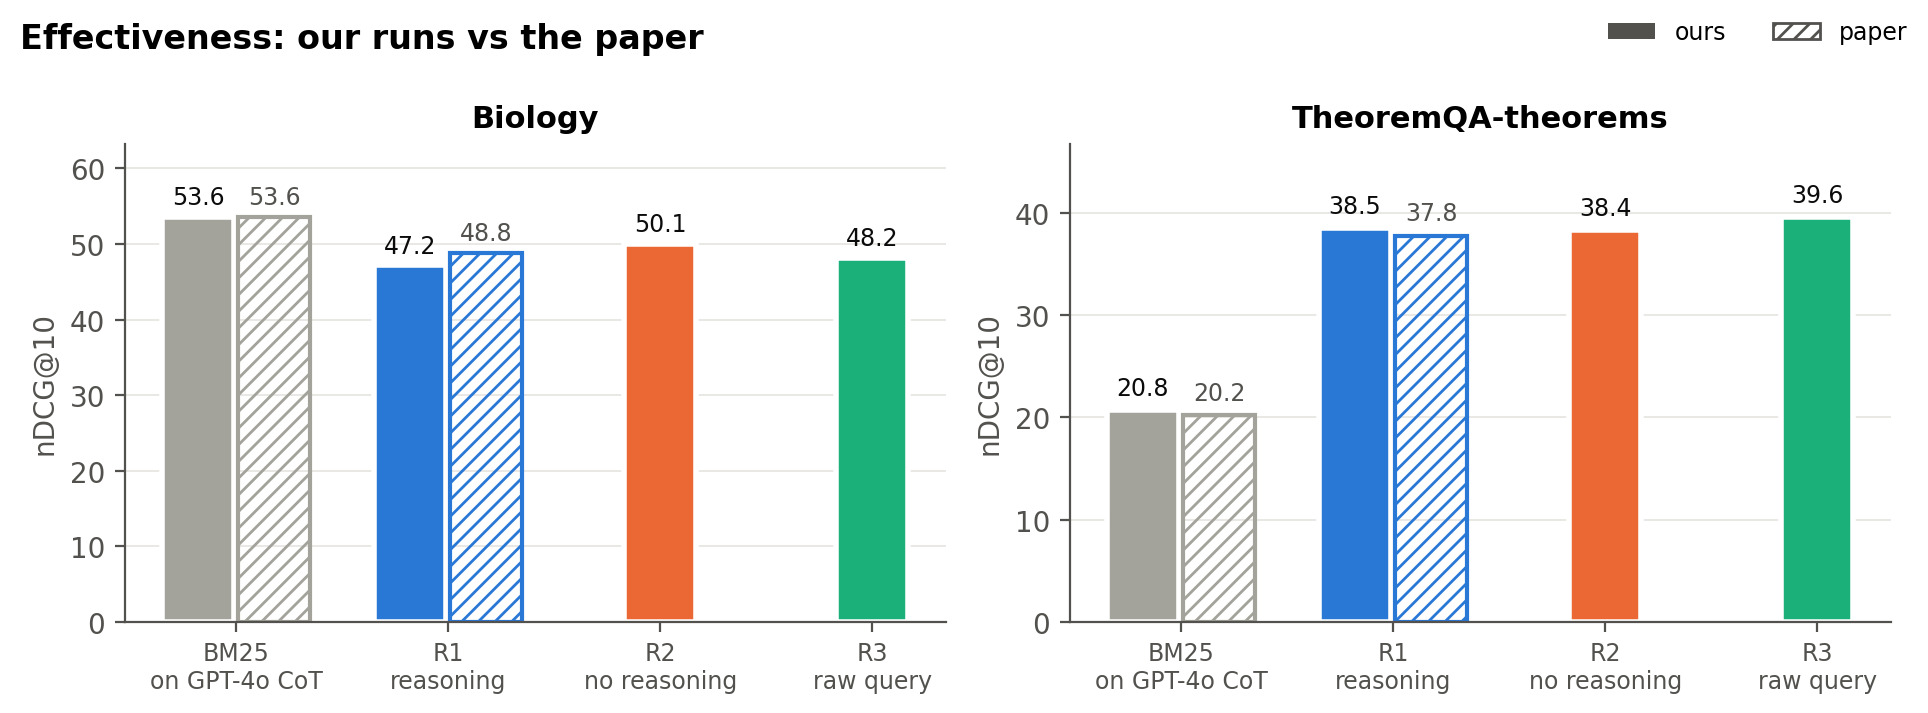

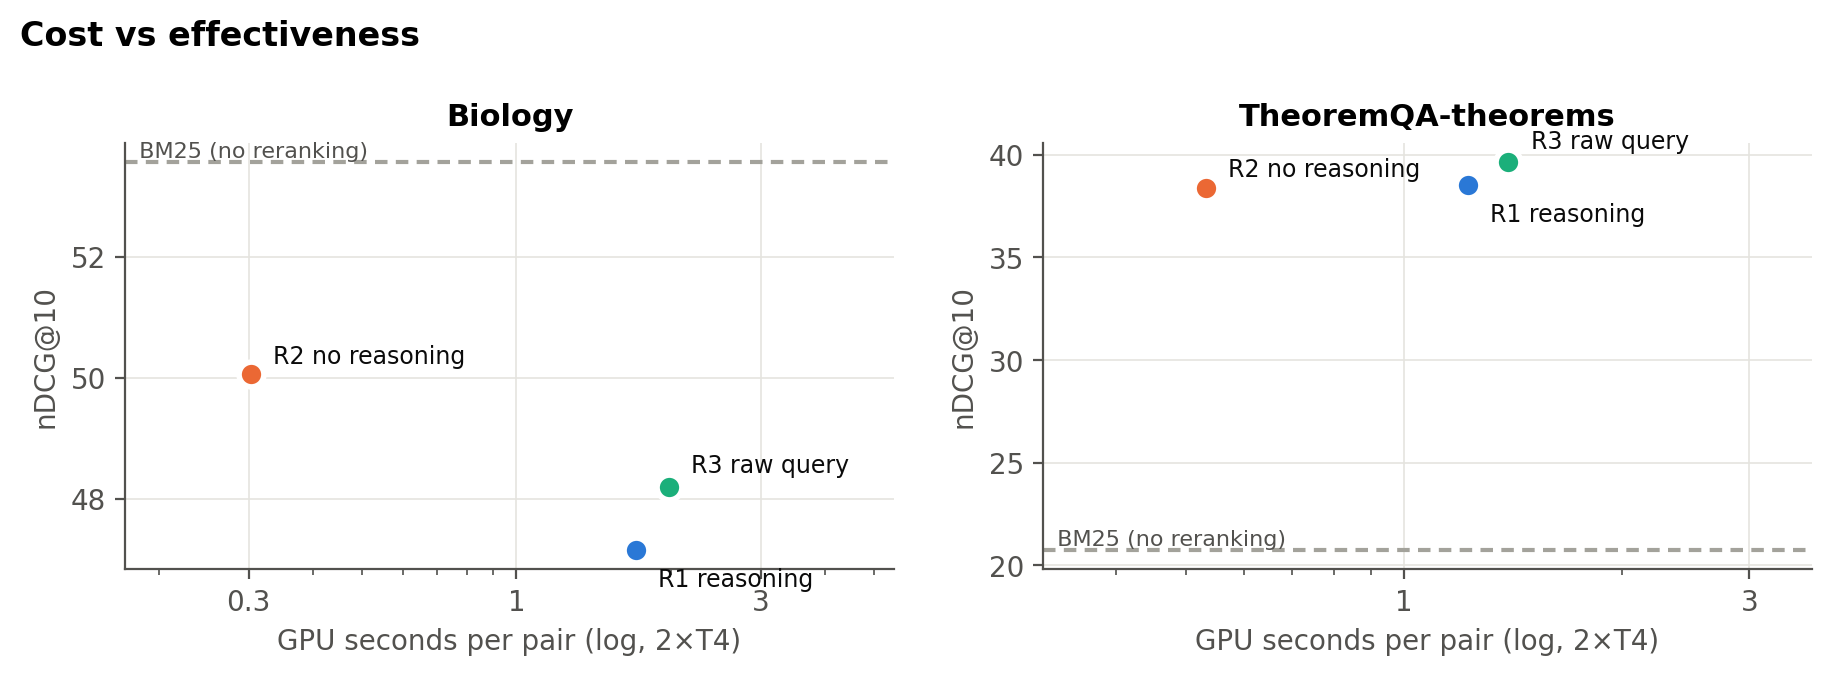

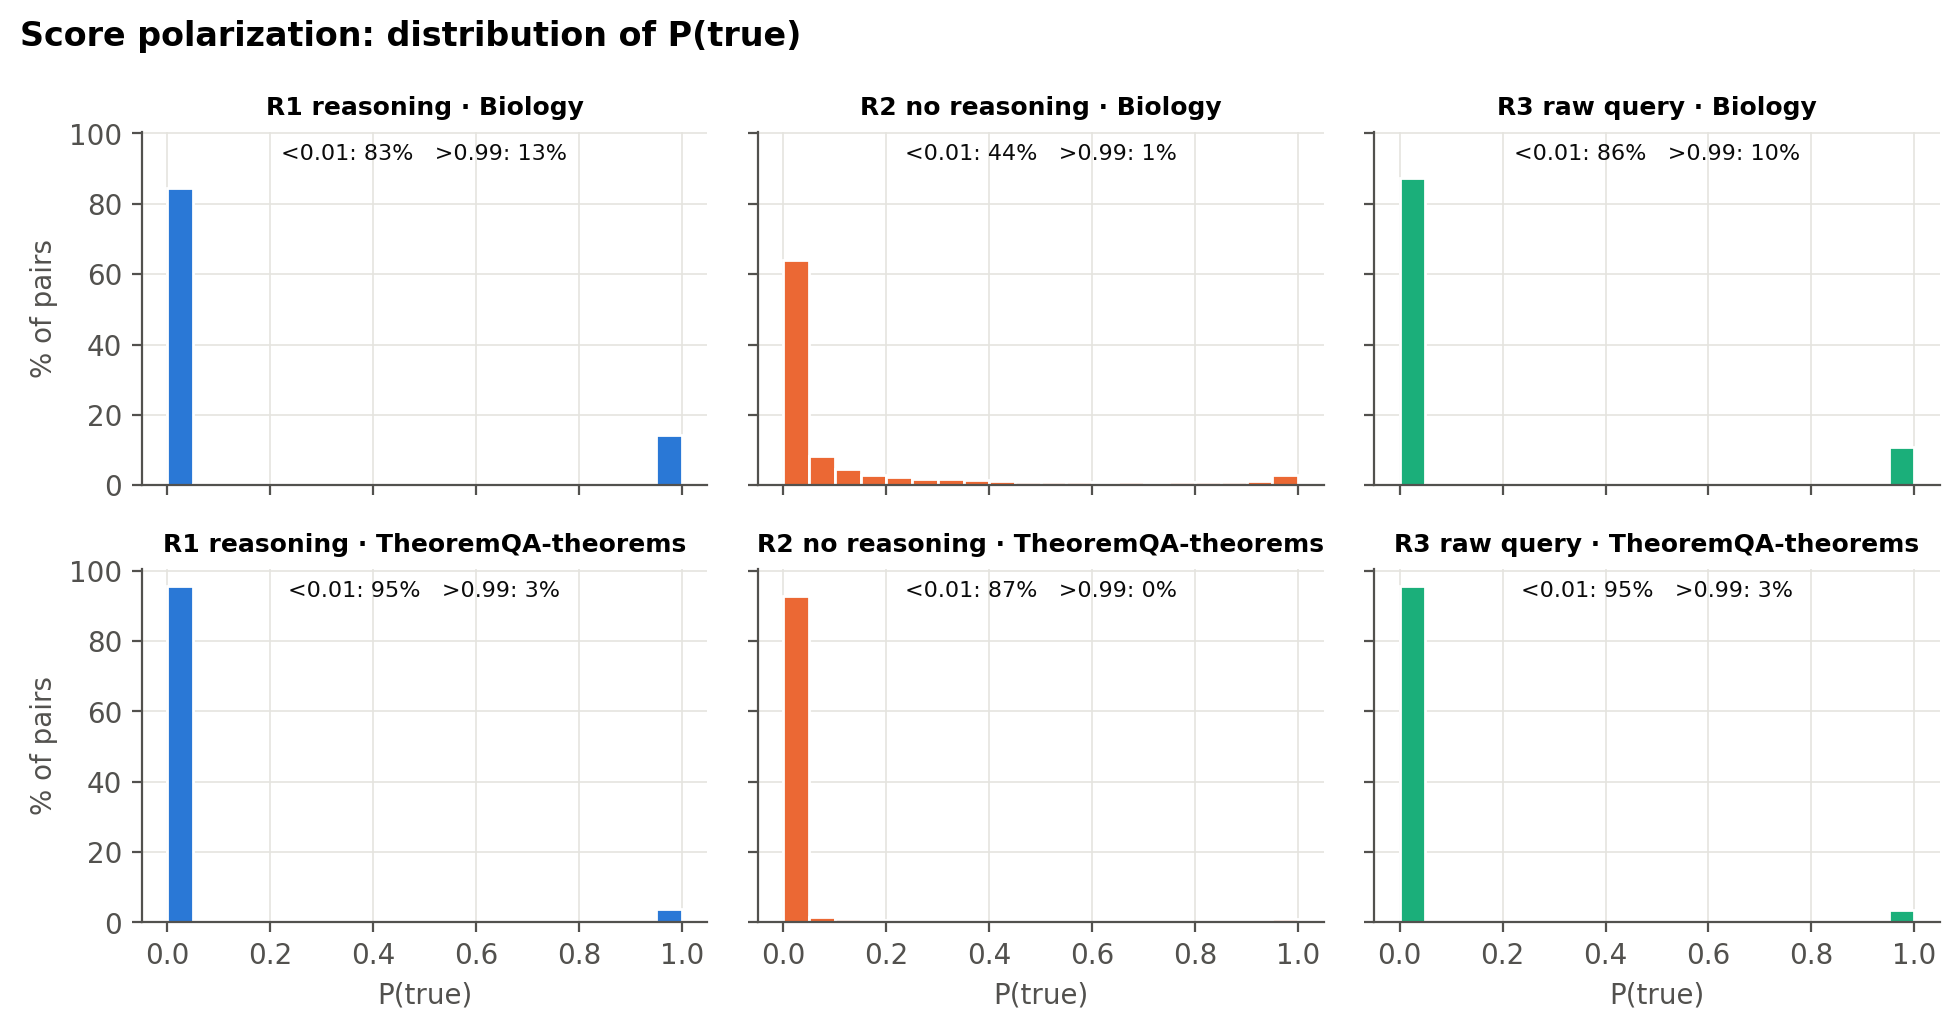

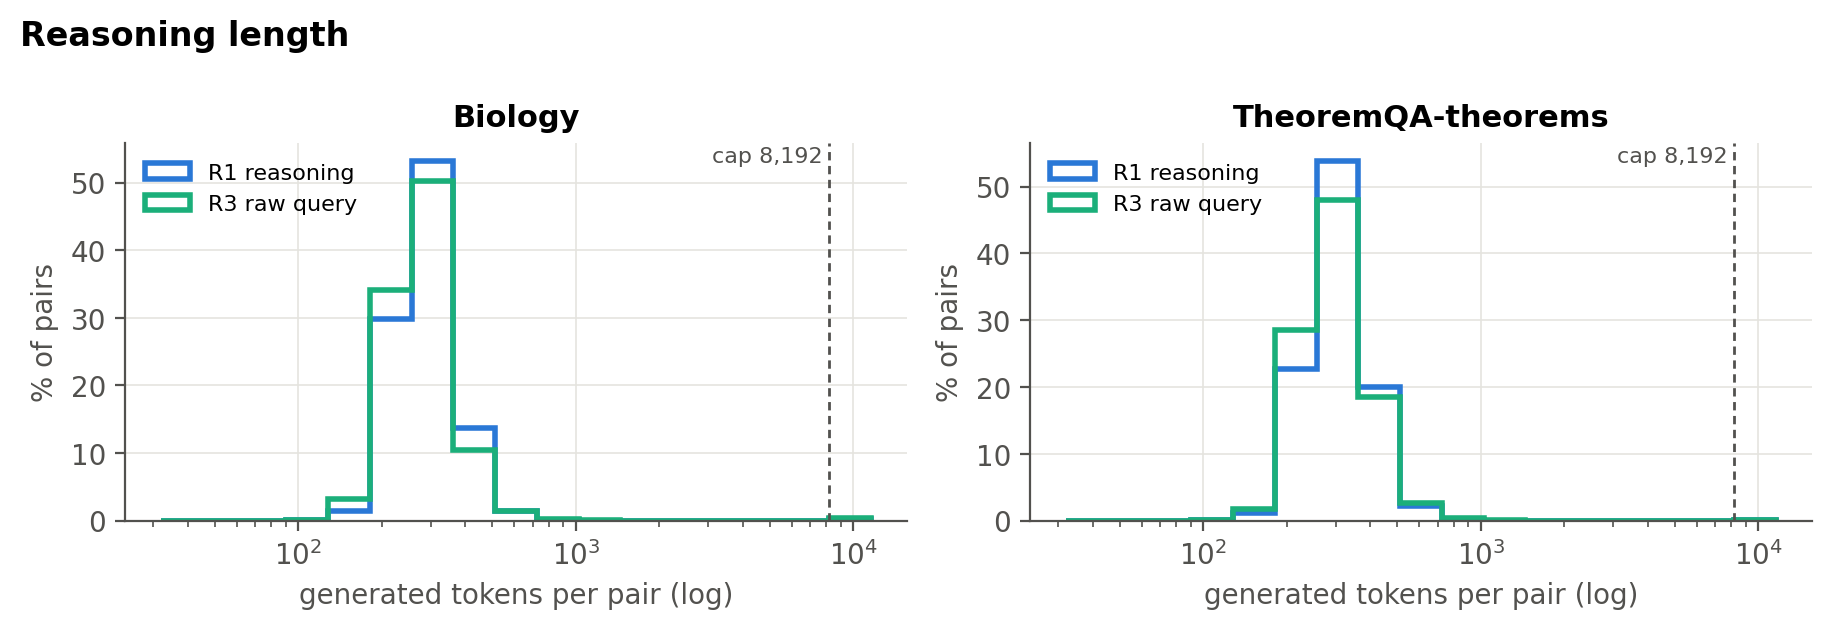

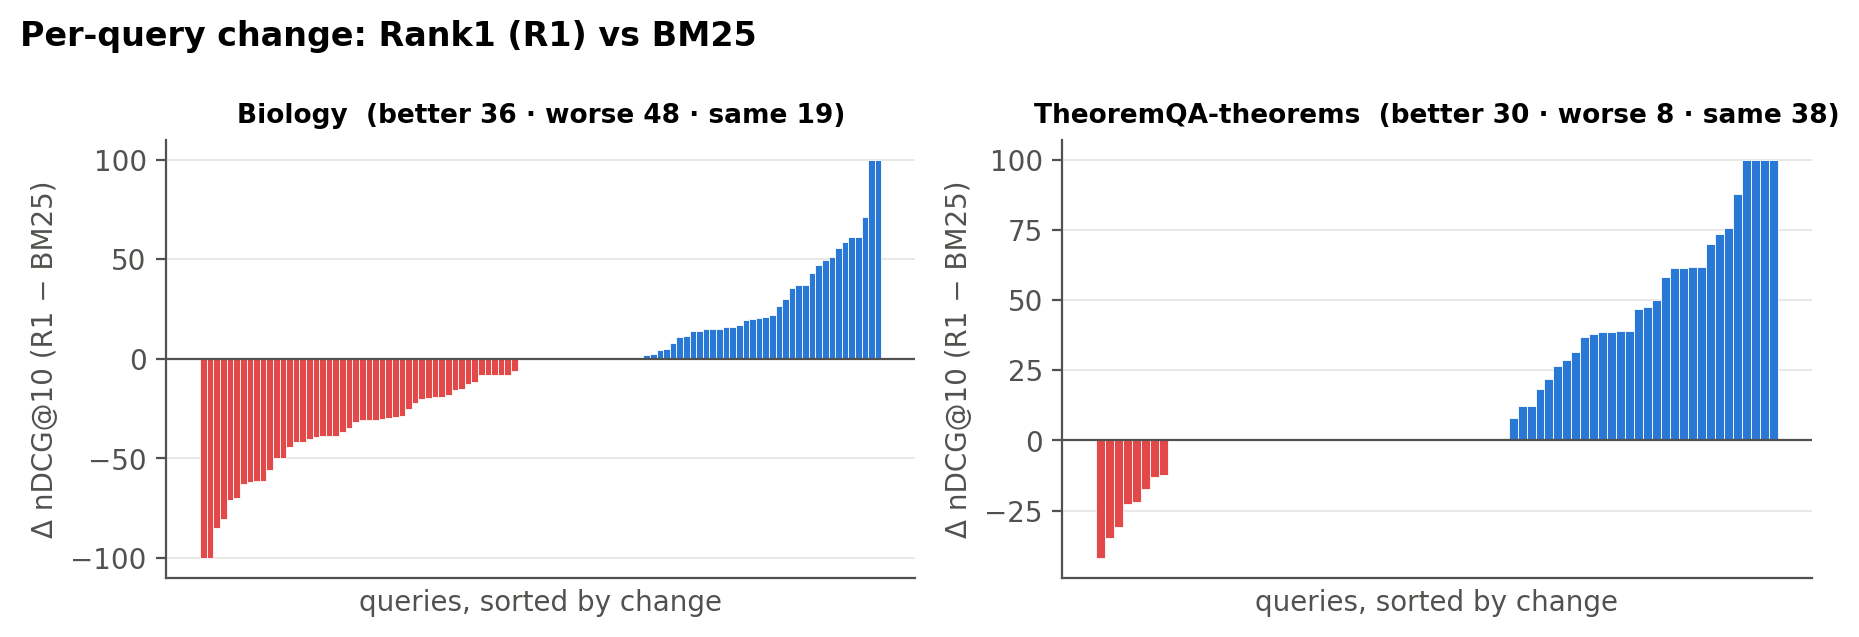

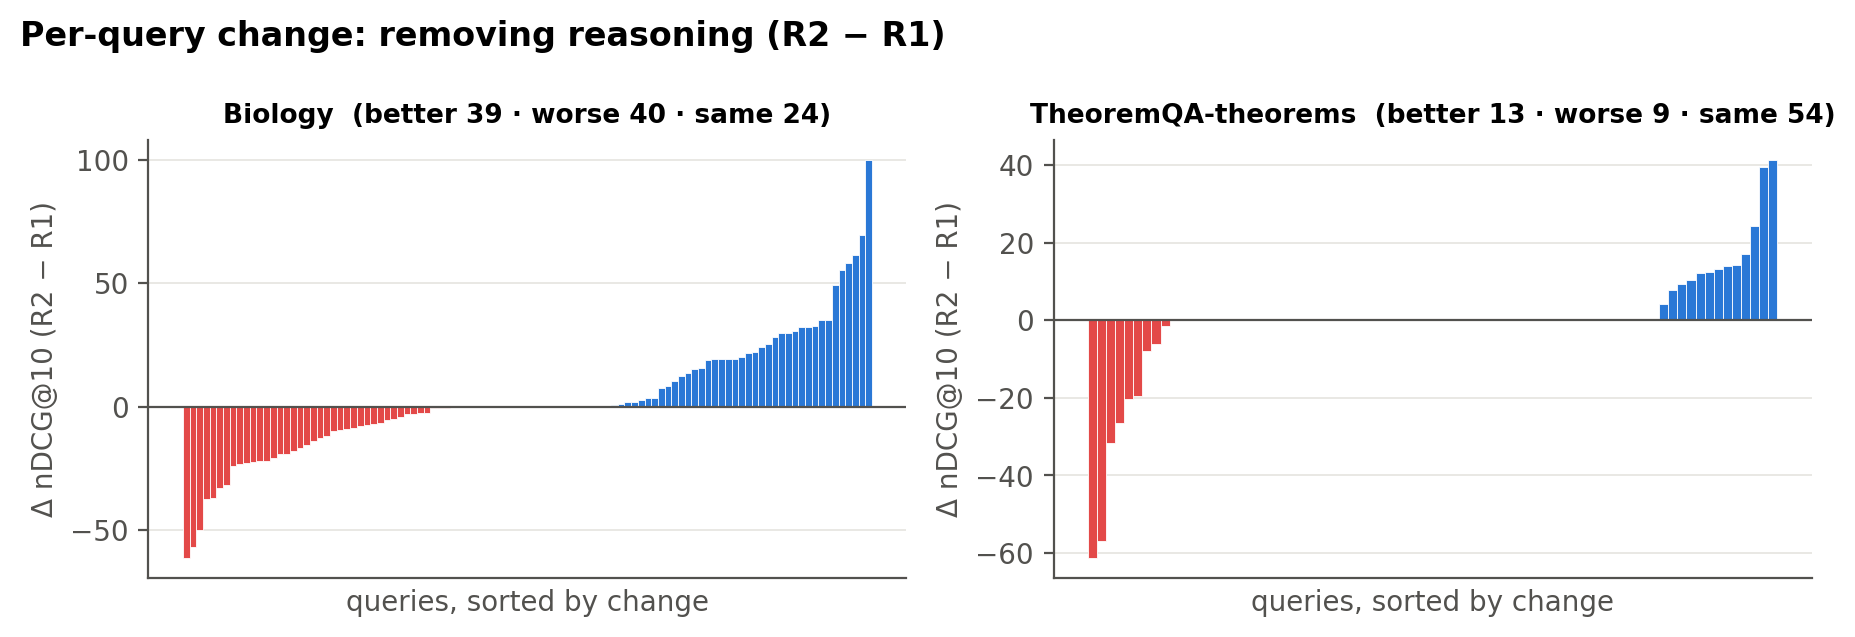

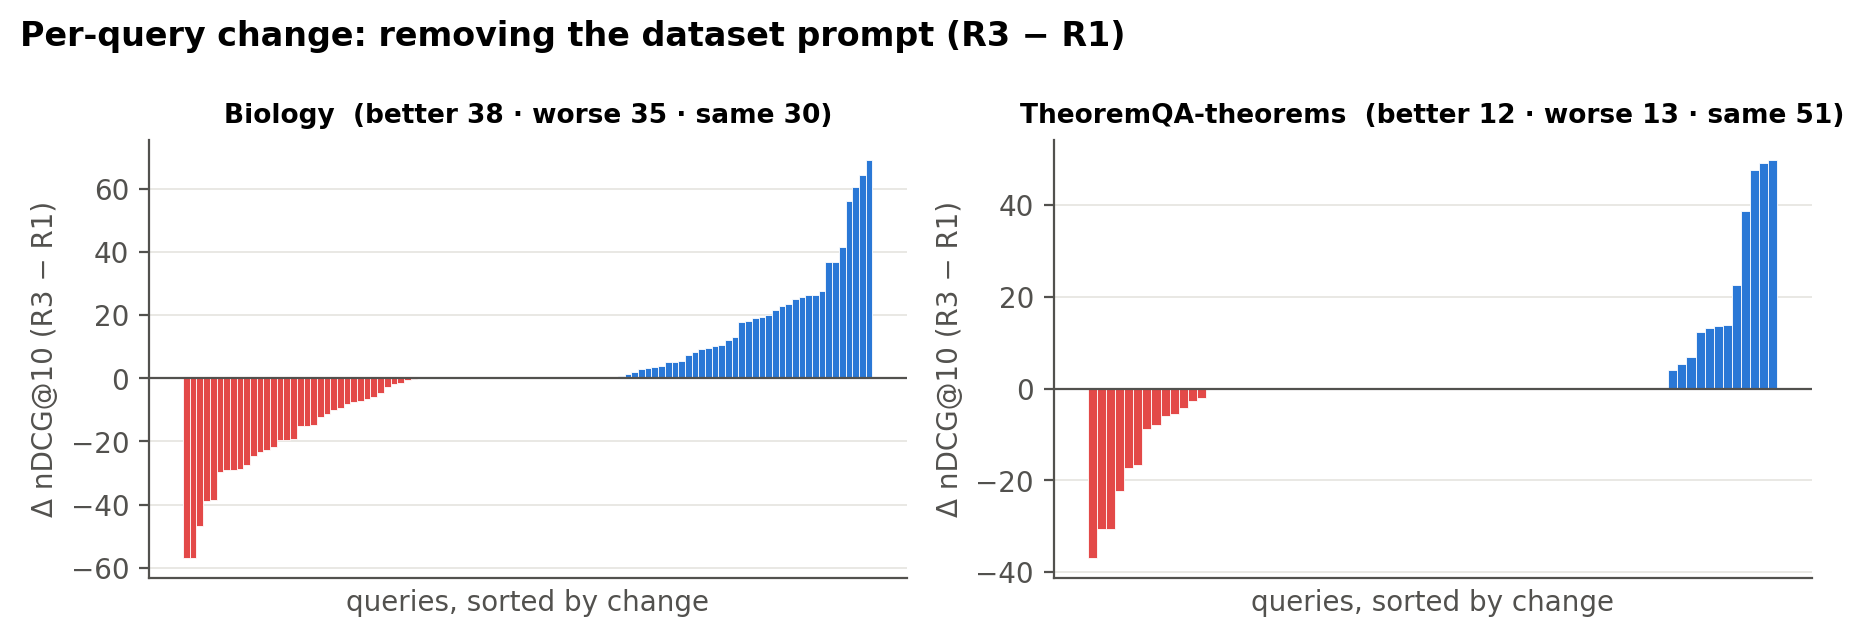

In [ ]:
os.chdir(WORK)
!python bright_report.py {WORK}/runs --out {WORK}/runs/report | head -1
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{WORK}/runs/report/tables.md").read()))
for f in sorted(glob.glob(f"{WORK}/runs/report/fig*.png")):
    display(Image(f, width=950))

In [ ]:
# runs, report and figures in one archive
!cd {WORK} && tar czf bright_runs_all.tgz runs && ls -lh bright_runs_all.tgz

-rw-r--r-- 1 root root 13M Nov 15 16:03 bright_runs_all.tgz
